In [1]:
import os
import numpy as np

In [2]:

import mediapipe as mp
import cv2
print("MediaPipe:", mp.__version__)
print("OpenCV:", cv2.__version__)



MediaPipe: 0.10.21
OpenCV: 4.8.1


In [3]:
!pip install -r requirements.txt

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached pytz-2025.2-py2.py3-none-any.whl.metadata (22 kB)
  Using cached tzdata-2025.2-py2.py3-none-any.whl.metadata (1.4 kB)
  Using cached joblib-1.5.2-py3-none-any.whl.metadata (5.6 kB)
  Using cached threadpoolctl-3.6.0-py3-none-any.whl.metadata (13 kB)
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ------ --------------------------------- 1.8/11.3 MB 12.6 MB/s eta 0:00:01
   ------------ --------------------------- 3.7/11.3 MB 10.4 MB/s eta 0:00:01
   ------------------- -------------------- 5.5/11.3 MB 9.9 MB/s eta 0:00:01
   -------------------------- ------------- 7.6/11.3 MB 10.0 MB/s eta 0:00:01
   -------------------------------- ------- 9.2/11.3 MB 9.5 MB/s eta 0:00:01
   ---------------------------------------  11.3/11.3 MB 9.8 MB/s eta 0:00:01
   ---------------------------------------- 11.3/11.3 MB 8.9 MB/s  0:00:01
   ---------------------------------------- 0.0/8.9 MB ? et

Dataset shape: (3032, 42)
Labels shape: (3032,)

✅ Model Accuracy: 99.18%

📊 Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.99        34
           1       1.00      0.97      0.98        33
           2       0.97      1.00      0.98        31
           3       1.00      1.00      1.00        40
           4       0.97      1.00      0.99        39
           5       1.00      0.95      0.97        41
           6       1.00      1.00      1.00        35
           7       1.00      1.00      1.00        35
           8       1.00      1.00      1.00        37
           9       1.00      1.00      1.00        41
           a       1.00      1.00      1.00         5
           b       0.93      1.00      0.96        13
           c       1.00      1.00      1.00         9
           d       1.00      1.00      1.00        14
           e       0.86      1.00      0.92         6
           f       1.00      1.00  

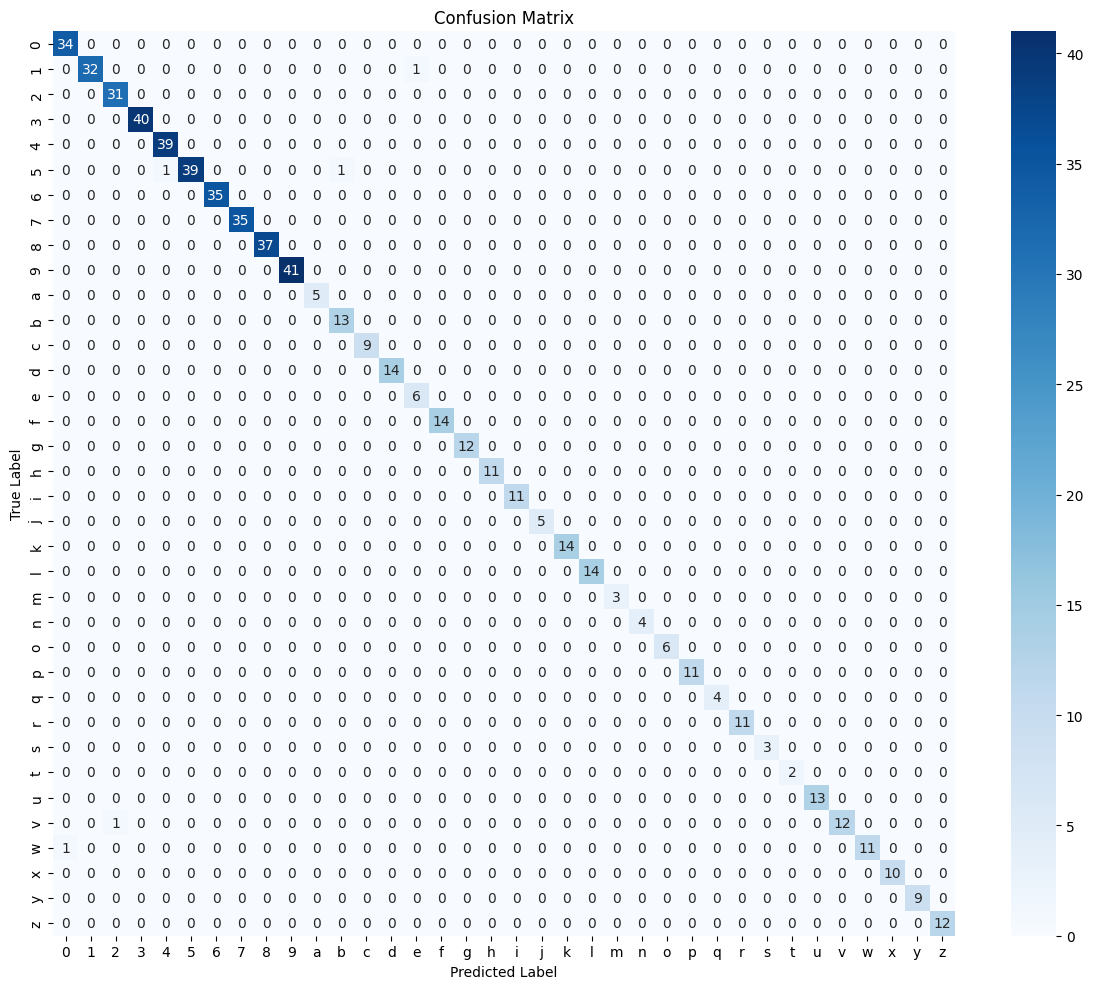

In [1]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
from sklearn.model_selection import train_test_split

# -------------------------------------------------
# 1. Load trained model
# -------------------------------------------------
model_dict = pickle.load(open('./model.p', 'rb'))
model = model_dict['model']

# -------------------------------------------------
# 2. Load dataset
# -------------------------------------------------
# ⚠️ IMPORTANT:
# This must match how you saved data during training
# Example assumes you saved data in data.pickle

data_dict = pickle.load(open('./data.pickle', 'rb'))

X = np.array(data_dict['data'])
y = np.array(data_dict['labels'])

print("Dataset shape:", X.shape)
print("Labels shape:", y.shape)

# -------------------------------------------------
# 3. Train / Test split (same as training)
# -------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# -------------------------------------------------
# 4. Predictions
# -------------------------------------------------
y_pred = model.predict(X_test)

# -------------------------------------------------
# 5. Accuracy
# -------------------------------------------------
accuracy = accuracy_score(y_test, y_pred)
print(f"\n✅ Model Accuracy: {accuracy * 100:.2f}%")

# -------------------------------------------------
# 6. Classification Report
# -------------------------------------------------
print("\n📊 Classification Report:")
print(classification_report(y_test, y_pred))

# -------------------------------------------------
# 7. Confusion Matrix
# -------------------------------------------------
cm = confusion_matrix(y_test, y_pred)
labels = np.unique(y_test)

# -------------------------------------------------
# 8. Confusion Matrix Graph
# -------------------------------------------------
plt.figure(figsize=(12, 10))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()
